# Overnight/Daytime Sign Agreement and Last-Half-Hour Momentum, CL 2021–2026 (#33)

This notebook collects the outputs of `src/analyze_sign_agreement.py`: the four ON/DAY sign categories, the two-dimensional (ON, DAY) view, the agreement regressions, their out-of-sample performance, the sign-filtered trading strategies and the robustness checks. It reads only the files the script writes and computes nothing the script does not. Run the script first, from the repository root:

```bash
python -m src.analyze_sign_agreement --config config/sign_agreement.yaml
```

The write-up is `reports/sign_agreement_results.md`. Means are in basis points with Newey-West standard errors; slopes are × 100.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

root = next(path for path in (Path("."), Path("..")) if (path / "reports/tables").exists())
tables = root / "reports/tables"
figures = root / "reports/figures"

manifest = json.loads((tables / "sign_agreement.manifest.json").read_text())
categories = pd.read_csv(tables / "sign_agreement_categories.csv")
grid = pd.read_csv(tables / "sign_agreement_grid.csv")
regressions = pd.read_csv(tables / "sign_agreement_regressions.csv")
oos = pd.read_csv(tables / "sign_agreement_oos.csv")
strategies = pd.read_csv(tables / "sign_agreement_strategies.csv")
by_year = pd.read_csv(tables / "sign_agreement_by_year.csv")
robustness = pd.read_csv(tables / "sign_agreement_robustness.csv")
robustness_terms = pd.read_csv(tables / "sign_agreement_robustness_regressions.csv")

pd.set_option("display.float_format", lambda value: f"{value:,.3f}")


def estimate(frame: pd.DataFrame, value: str, error: str) -> pd.Series:
	return frame.apply(lambda row: f"{row[value]:.2f} ({row[error]:.2f})" if pd.notna(row[value]) else "", axis=1)

## 1. Sample and categories

Signs of ON (previous 13:30 to 08:00 CT) and DAY (08:00 to 13:00 CT) are known at 13:00 CT. The four categories, the pooled agreement and disagreement groups, the handful of zero-return days, and the agree-minus-disagree difference in the paper's strategy return η = sign(ROD) × LH.

In [2]:
pd.Series(
	{
		"trade dates": manifest["sample"]["observations"],
		"dates": manifest["sample"]["dates"],
		"zero-return days (set aside)": manifest["sample"]["zero_return_days"],
		"category counts": manifest["category_counts"],
		"Newey-West lags": manifest["hac_lags_used"],
		"first out-of-sample forecast": manifest["sample"]["first_oos_forecast"],
		"Bonferroni level (5 comparisons)": f"{manifest['bonferroni_level']:.3f}",
	},
	name="value",
).to_frame()

,value
trade dates,1436
dates,2021-01-04 to 2026-10-07
zero-return days (set aside),12
category counts,"{'ON+/DAY+': 415, 'ON+/DAY-': 377, 'ON-/DAY+':..."
Newey-West lags,7
first out-of-sample forecast,2023-01-04
Bonferroni level (5 comparisons),0.010


In [3]:
table = categories.assign(mean_lh=estimate(categories, "mean_lh_bps", "se_lh_bps"), eta=estimate(categories, "eta_bps", "se_eta_bps"))
table[["group", "kind", "n", "mean_lh", "sd_lh_pct", "lh_follows_rod", "lh_follows_rod_se", "eta", "ci_low_eta_bps", "ci_high_eta_bps", "t_eta", "p_eta"]].rename(
	columns={"mean_lh": "mean LH bps (SE)", "eta": "sign(ROD) x LH bps (SE)"}
)

,group,kind,n,mean LH bps (SE),sd_lh_pct,lh_follows_rod,lh_follows_rod_se,sign(ROD) x LH bps (SE),ci_low_eta_bps,ci_high_eta_bps,t_eta,p_eta
0,ON+/DAY+,category,415,-4.11 (1.90),0.438,0.470,0.024,-4.11 (1.90),-7.837,-0.375,-2.157,NaN
1,ON-/DAY-,category,305,5.00 (3.06),0.562,0.469,0.029,-5.00 (3.06),-11.003,1.009,-1.631,NaN
2,ON+/DAY-,category,377,-3.69 (2.29),0.447,0.509,0.026,2.10 (2.32),-2.451,6.653,0.905,NaN
3,ON-/DAY+,category,327,-1.07 (2.48),0.433,0.462,0.028,1.62 (2.42),-3.128,6.377,0.670,NaN
4,agree,pooled,720,-0.25 (1.56),0.496,0.469,0.019,-4.48 (1.71),-7.830,-1.137,-2.626,NaN
5,disagree,pooled,704,-2.47 (1.62),0.441,0.487,0.019,1.88 (1.82),-1.684,5.443,1.034,NaN
6,zero,excluded,12,-9.97 (12.99),0.425,0.667,0.136,16.96 (4.14),8.847,25.071,4.097,NaN
7,agree - disagree,difference,1424,,NaN,-0.018,0.025,-6.36 (2.34),-10.950,-1.777,-2.719,0.007


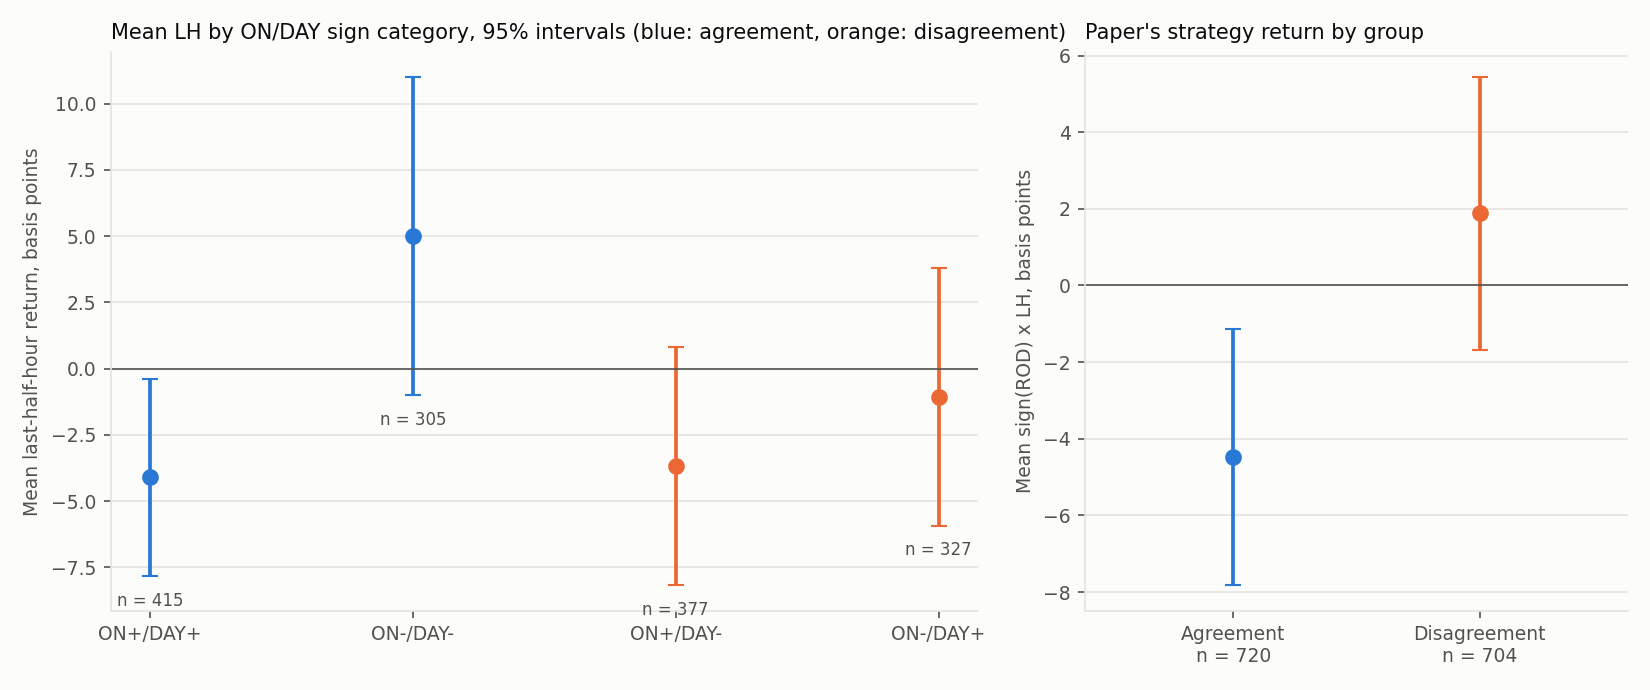

In [4]:
display(Image(filename=figures / "sign_agreement_categories.png", width=950))

## 2. The two-dimensional view

ON and DAY as a vector: mean LH on the tercile grid, and the regressions with the ON × DAY product and the agreement interactions.

In [5]:
grid.assign(mean_lh=estimate(grid, "mean_lh_bps", "se_lh_bps"), eta=estimate(grid, "eta_bps", "se_eta_bps")).pivot(index="on_bin", columns="day_bin", values="mean_lh").reindex(index=["high", "mid", "low"], columns=["low", "mid", "high"])

day_bin,low,mid,high
on_bin,,,
high,-8.17 (4.49),0.39 (2.76),-5.55 (3.62)
mid,2.73 (3.22),-1.07 (2.64),-7.07 (2.80)
low,6.93 (4.99),0.35 (3.64),-1.22 (3.91)


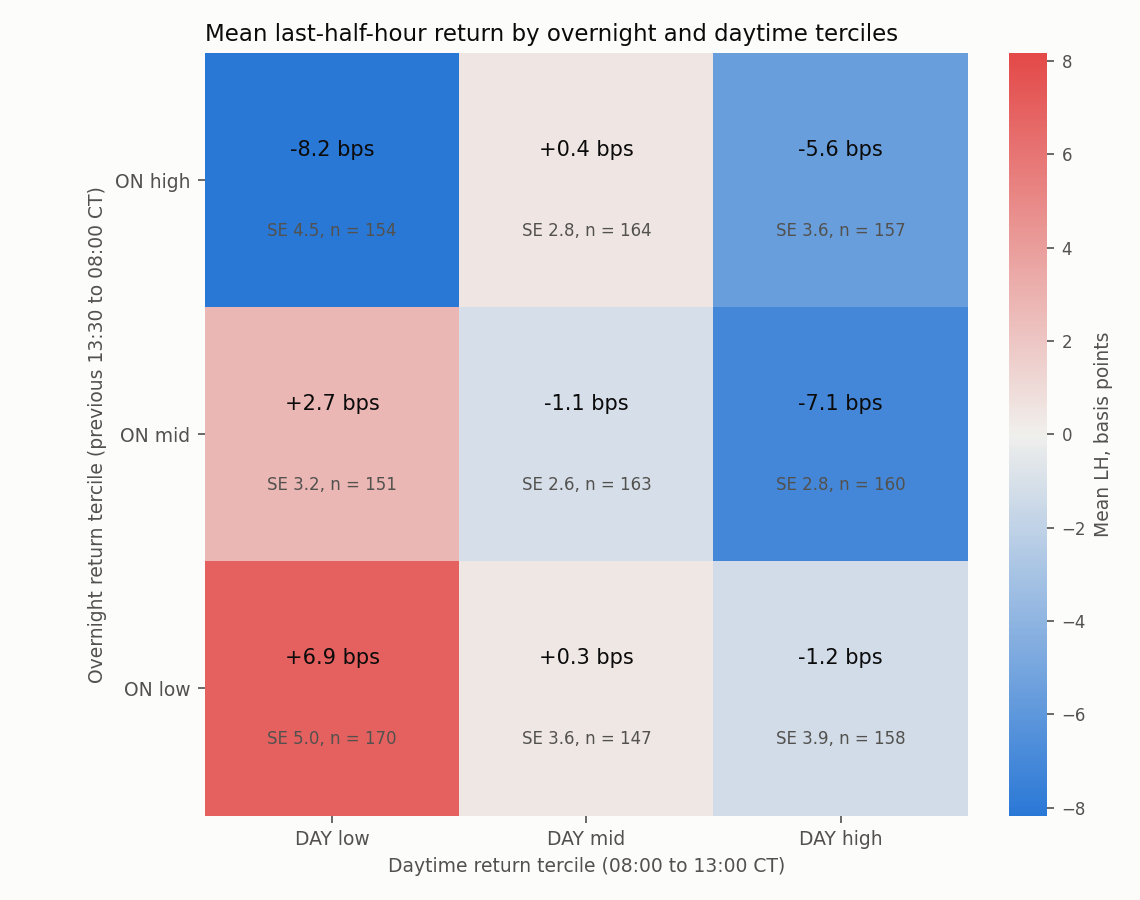

In [6]:
display(Image(filename=figures / "sign_agreement_grid.png", width=640))

In [7]:
fit = regressions.assign(estimate=estimate(regressions, "coef_x100", "se_x100"))
fit[["model", "term", "estimate", "ci_low_x100", "ci_high_x100", "t_stat", "p_value", "adj_r2_pct"]].rename(columns={"estimate": "coef x 100 (SE)"})

,model,term,coef x 100 (SE),ci_low_x100,ci_high_x100,t_stat,p_value,adj_r2_pct
0,rod,const,-0.01 (0.01),-0.036,0.012,-0.998,0.318,0.524
1,rod,rod,-1.46 (0.97),-3.349,0.435,-1.510,0.131,0.524
2,rod_by_agreement,const,-0.03 (0.02),-0.058,0.006,-1.598,0.110,1.709
3,rod_by_agreement,rod,2.36 (1.23),-0.052,4.769,1.918,0.055,1.709
4,rod_by_agreement,agree,0.03 (0.02),-0.017,0.079,1.261,0.207,1.709
5,rod_by_agreement,rod_x_agree,-5.00 (1.60),-8.142,-1.857,-3.118,0.002,1.709
6,on_day,const,-0.01 (0.01),-0.036,0.011,-1.019,0.308,0.519
7,on_day,on,-1.26 (1.01),-3.246,0.721,-1.248,0.212,0.519
8,on_day,day,-1.84 (1.43),-4.643,0.968,-1.284,0.199,0.519
9,on_day_product,const,-0.01 (0.01),-0.034,0.013,-0.895,0.371,1.880


## 3. Out of sample

Expanding-window forecasts after 500 observations, against the historical mean and against the model each interaction model nests (Clark-West).

In [8]:
oos[["model", "n", "adj_r2_pct", "wald_df", "wald_p", "oos_forecasts", "oos_r2_pct", "clark_west_t", "clark_west_p", "nested_in", "oos_r2_vs_nested_pct", "clark_west_t_vs_nested", "clark_west_p_vs_nested"]]

,model,n,adj_r2_pct,wald_df,wald_p,oos_forecasts,oos_r2_pct,clark_west_t,clark_west_p,nested_in,oos_r2_vs_nested_pct,clark_west_t_vs_nested,clark_west_p_vs_nested
0,rod,1436,0.524,NaN,NaN,936,0.368,1.002,0.158,NaN,NaN,NaN,NaN
1,rod_by_agreement,1436,1.709,1.000,0.002,936,0.746,1.621,0.052,rod,0.380,1.585,0.056
2,on_day,1436,0.519,NaN,NaN,936,-0.294,0.335,0.369,NaN,NaN,NaN,NaN
3,on_day_product,1436,1.880,1.000,0.021,936,-0.603,0.599,0.275,on_day,-0.308,0.714,0.238
4,on_day_by_agreement,1436,2.472,2.000,0.004,936,-0.188,1.069,0.142,on_day,0.105,1.294,0.098


## 4. Trading comparison

Sign-filtered strategies priced with the #30 fills and costs. The baseline row reproduces the #30 result.

In [9]:
strategies.assign(mean=estimate(strategies, "mean_bps", "se_hac_bps"), sharpe=estimate(strategies, "sharpe", "sharpe_se"))[
	["strategy", "accounting", "traded_days", "mean", "ci_low_bps", "ci_high_bps", "sharpe", "hit_rate", "total_pnl_usd", "max_drawdown_usd", "total_cost_usd"]
].rename(columns={"mean": "mean bps (SE)", "sharpe": "Sharpe (SE)"})

,strategy,accounting,traded_days,mean bps (SE),ci_low_bps,ci_high_bps,Sharpe (SE),hit_rate,total_pnl_usd,max_drawdown_usd,total_cost_usd
0,rod,frictionless,1435,-1.18 (1.26),-3.656,1.287,-0.40 (0.42),0.480,NaN,NaN,NaN
1,rod,gross,1435,-1.15 (1.26),-3.621,1.319,-0.39 (0.42),0.481,"-9,570.000","23,380.000","21,525.000"
2,rod,net,1435,-3.15 (1.26),-5.621,-0.677,-1.07 (0.42),0.466,"-31,095.000","39,235.000","21,525.000"
3,agree_only,frictionless,720,-2.25 (0.87),-3.948,-0.548,-1.02 (0.42),0.469,NaN,NaN,NaN
4,agree_only,gross,720,-2.19 (0.87),-3.899,-0.489,-0.99 (0.42),0.474,"-24,850.000","29,030.000","10,800.000"
5,agree_only,net,720,-3.19 (0.87),-4.904,-1.485,-1.44 (0.42),0.457,"-35,650.000","39,055.000","10,800.000"
6,disagree_only,frictionless,703,0.92 (0.84),-0.734,2.577,0.47 (0.42),0.488,NaN,NaN,NaN
7,disagree_only,gross,703,0.90 (0.84),-0.754,2.549,0.46 (0.42),0.485,"13,600.000","6,480.000","10,545.000"
8,disagree_only,net,703,-0.08 (0.84),-1.733,1.567,-0.04 (0.42),0.471,"3,055.000","11,685.000","10,545.000"
9,day_sign,frictionless,1432,-1.45 (1.14),-3.691,0.783,-0.49 (0.42),0.484,NaN,NaN,NaN


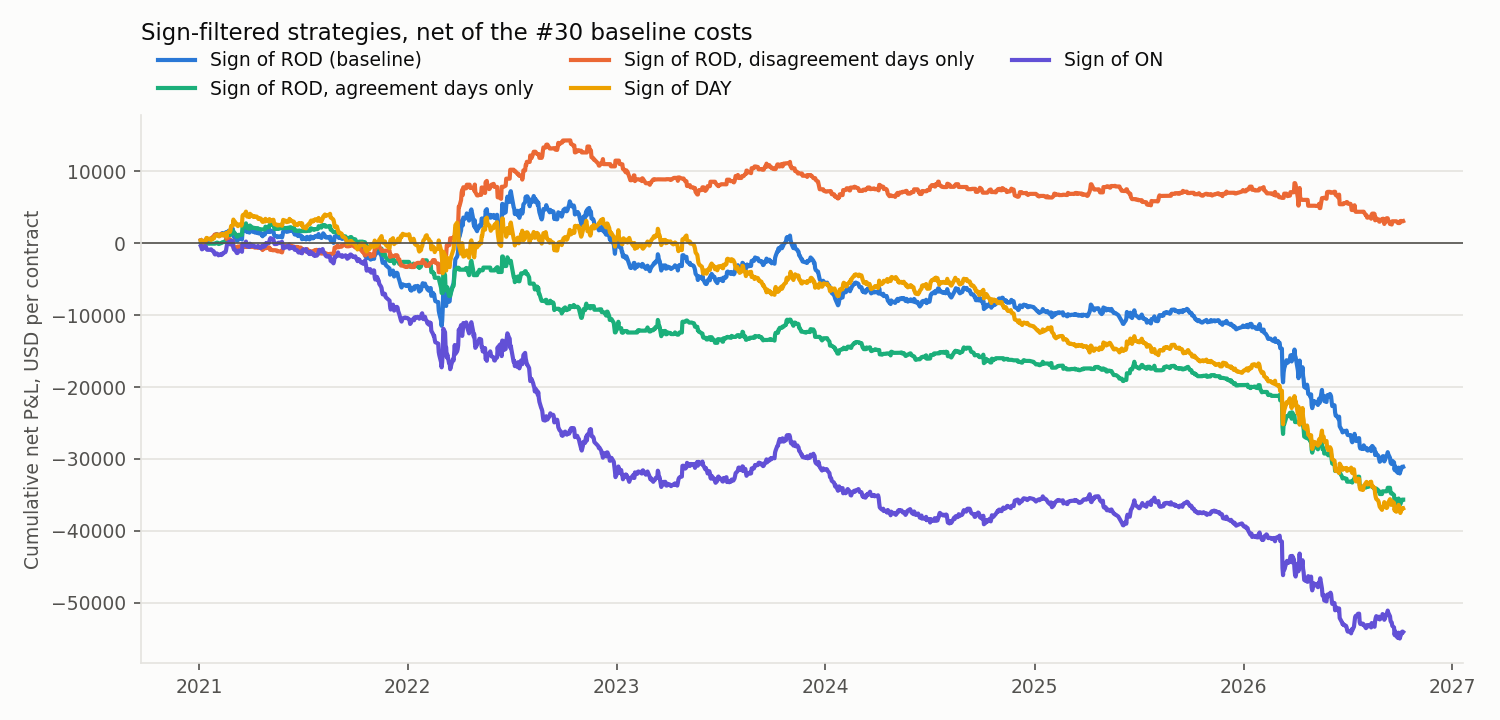

In [10]:
display(Image(filename=figures / "sign_agreement_cumulative.png", width=950))

## 5. Stability and robustness

In [11]:
by_year.assign(eta=estimate(by_year, "eta_bps", "se_eta_bps"))[["year", "group", "n", "eta", "t_eta", "lh_follows_rod"]].rename(columns={"eta": "sign(ROD) x LH bps (SE)"})

,year,group,n,sign(ROD) x LH bps (SE),t_eta,lh_follows_rod
0,2021,agree,114,-0.57 (3.82),-0.149,0.491
1,2021,disagree,136,-0.74 (3.60),-0.204,0.471
2,2021,agree - disagree,250,0.17 (5.31),0.031,NaN
3,2022,agree,128,-7.63 (4.81),-1.587,0.461
4,2022,disagree,119,13.49 (6.72),2.007,0.563
5,2022,agree - disagree,247,-21.12 (7.69),-2.746,NaN
6,2023,agree,129,0.42 (4.13),0.101,0.535
7,2023,disagree,117,-3.16 (4.26),-0.743,0.444
8,2023,agree - disagree,246,3.58 (4.98),0.719,NaN
9,2024,agree,124,-2.34 (2.70),-0.866,0.460


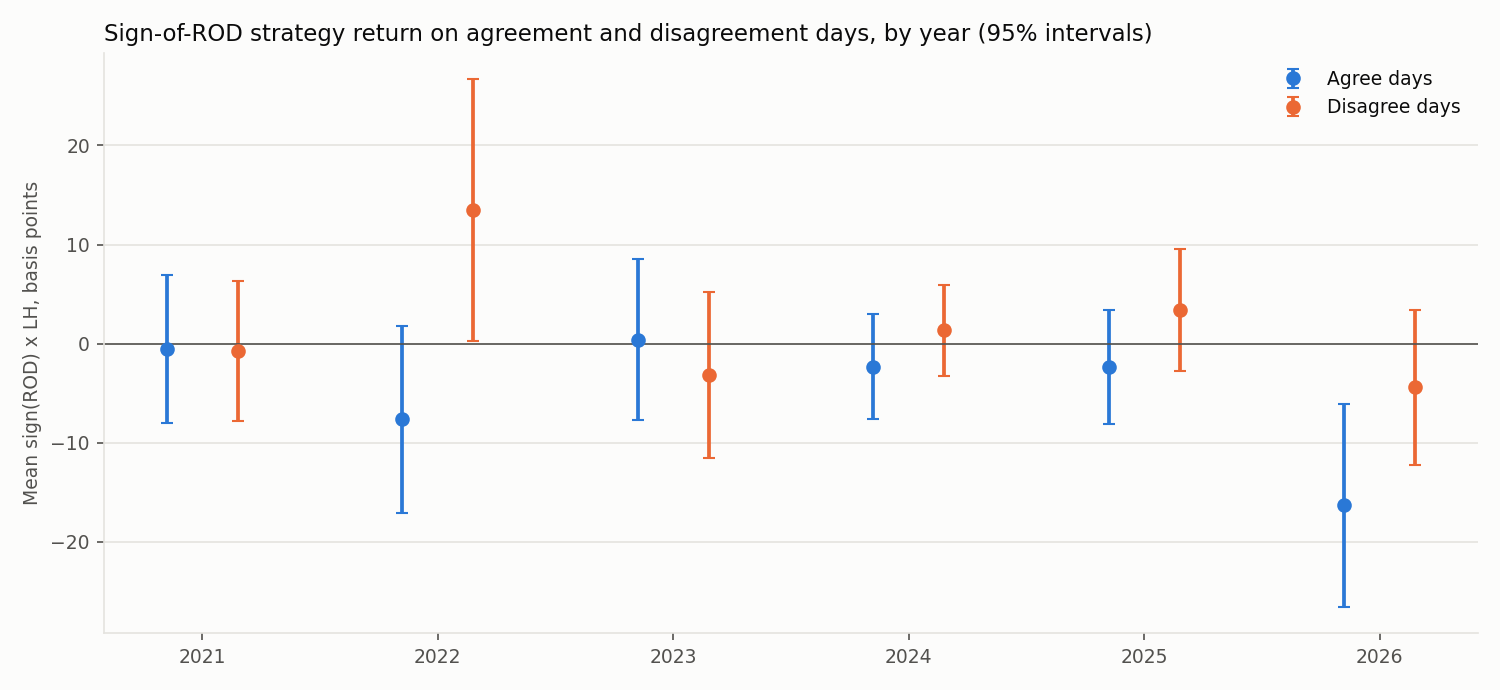

In [12]:
display(Image(filename=figures / "sign_agreement_by_year.png", width=950))

In [13]:
difference = robustness[robustness["group"].eq("agree - disagree")].assign(difference=estimate(robustness, "eta_bps", "se_eta_bps"))[["variant", "dropped", "n", "difference", "p_eta"]]
interactions = robustness_terms[robustness_terms["term"].isin(["rod_x_agree", "day_x_agree", "on_x_day"])].assign(estimate=estimate(robustness_terms, "coef_x100", "se_x100"))
difference.merge(interactions.pivot(index="variant", columns="term", values="estimate"), on="variant").rename(columns={"difference": "agree - disagree bps (SE)"})

,variant,dropped,n,agree - disagree bps (SE),p_eta,day_x_agree,on_x_day,rod_x_agree
0,exclude:exclude_2026_03_10,1,1423,-5.74 (2.27),0.011,-7.57 (2.49),46.02 (37.95),-4.00 (1.38)
1,exclude:exclude_roll_dates,69,1355,-7.18 (2.37),0.002,-10.98 (3.51),117.99 (48.37),-5.41 (1.61)
2,exclude:exclude_degraded_dates,12,1412,-6.89 (2.38),0.004,-9.96 (3.42),108.50 (46.79),-5.18 (1.63)
3,exclude:exclude_after_non_trading_days,304,1124,-6.73 (2.69),0.012,-11.34 (4.08),140.23 (81.31),-6.19 (1.84)
4,log_returns,0,1424,-6.36 (2.34),0.007,-10.13 (3.43),113.39 (46.94),-5.08 (1.61)
